In [1]:
# 202431051 - Artika Aulia S
# 1. Import Pustaka dan Konfigurasi Lingkungan Kerja
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Konfigurasi Tampilan Visualisasi (Bersih & Tanpa Watermark Gambar)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
print("Pustaka berhasil di-import!")


Pustaka berhasil di-import!


In [2]:
# 202431051 - Artika Aulia S
# 2. Ingestion dan Inspeksi Struktur Dataset CS2
df = pd.read_csv("03_counter_strike_2.csv")
print("=== Dimensi Dataset ===")
print(f"Jumlah Baris: {df.shape[0]}, Jumlah Kolom: {df.shape[1]}")
print("=== Tipe Data Setiap Kolom ===")
print(df.dtypes)
print("=== 5 Sampel Teratas ===")
df.head()


=== Dimensi Dataset ===
Jumlah Baris: 2000, Jumlah Kolom: 14
=== Tipe Data Setiap Kolom ===
time_left       float64
ct_score        float64
t_score         float64
map                 str
bomb_planted       bool
ct_health       float64
t_health        float64
ct_armor        float64
t_armor         float64
ct_money        float64
t_money         float64
ct_helmets      float64
t_helmets       float64
round_winner        str
dtype: object
=== 5 Sampel Teratas ===


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT


In [3]:
# 202431051 - Artika Aulia S
# 3. Data Cleaning: Cek Nilai Hilang (Missing Values) dan Duplikat
print("=== Ringkasan Missing Values ===")
print(df.isnull().sum())
print(f"Jumlah Baris Duplikat: {df.duplicated().sum()}")
print("=== Ringkasan Statistik Deskriptif Fitur Numerik ===")
df.describe().T


=== Ringkasan Missing Values ===
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted    0
ct_health       0
t_health        0
ct_armor        0
t_armor         0
ct_money        0
t_money         0
ct_helmets      0
t_helmets       0
round_winner    0
dtype: int64
Jumlah Baris Duplikat: 39
=== Ringkasan Statistik Deskriptif Fitur Numerik ===


,count,mean,std,min,25%,50%,75%,max
time_left,2000.0,95.630205,53.734491,0.05,54.91,94.91,156.425,175.0
ct_score,2000.0,6.840000,4.233599,0.00,3.00,7.00,10.000,15.0
t_score,2000.0,6.288500,4.190590,0.00,3.00,6.00,10.000,15.0
ct_health,2000.0,406.170500,137.616258,2.00,315.75,500.00,500.000,500.0
t_health,2000.0,402.987500,137.699186,0.00,328.75,500.00,500.000,500.0
ct_armor,2000.0,306.749000,172.857221,0.00,188.00,300.00,488.000,500.0
t_armor,2000.0,309.544500,168.689570,0.00,190.00,362.00,467.000,500.0
ct_money,2000.0,7867.350000,9017.491838,0.00,1200.00,4000.00,11762.500,58050.0
t_money,2000.0,12377.600000,12209.581798,0.00,1700.00,9075.00,19250.000,67700.0
ct_helmets,2000.0,1.821500,1.774884,0.00,0.00,1.00,3.000,5.0


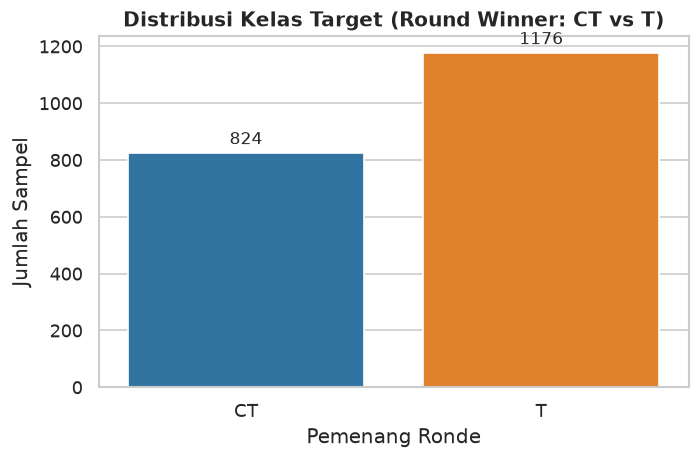

In [4]:
# 202431051 - Artika Aulia S
# 4. EDA: Visualisasi Distribusi Variabel Target (round_winner)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="round_winner", palette=["#1f77b4", "#ff7f0e"], hue="round_winner", legend=False)
plt.title("Distribusi Kelas Target (Round Winner: CT vs T)", fontsize=12, fontweight="bold")
plt.xlabel("Pemenang Ronde")
plt.ylabel("Jumlah Sampel")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()


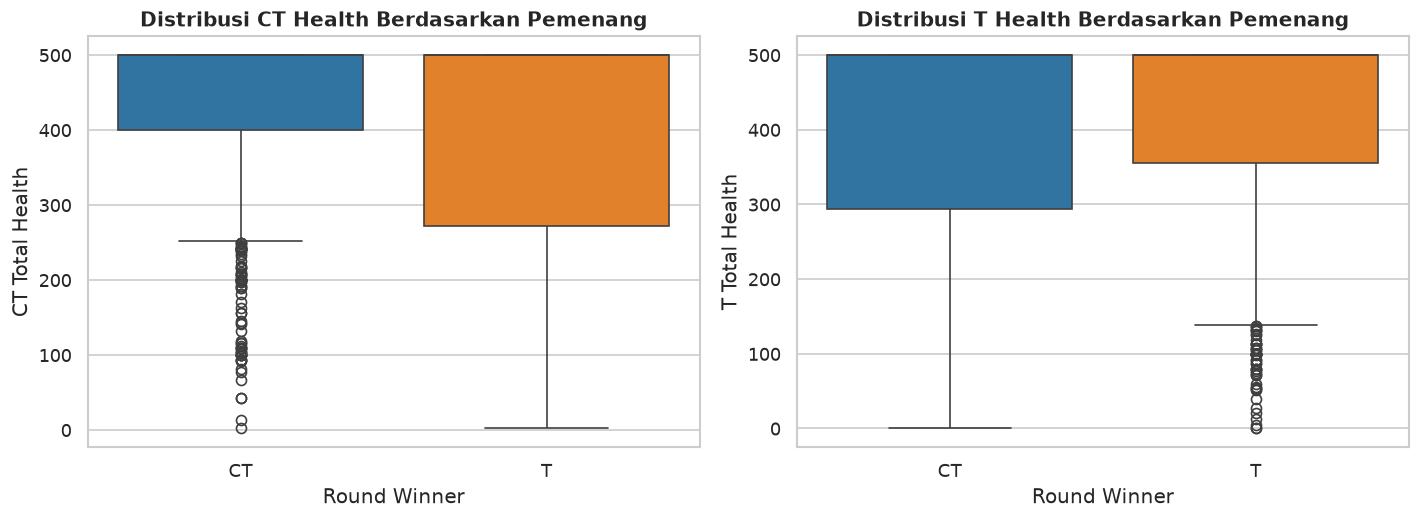

In [5]:
# 202431051 - Artika Aulia S
# 5. EDA: Visualisasi Fitur Kesehatan dan Armor Antar Tim
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# Grafik pertama
sns.boxplot(data=df, x="round_winner", y="ct_health", hue="round_winner", palette=["#1f77b4", "#ff7f0e"], legend=False, ax=axes[0])
axes[0].set_title("Distribusi CT Health Berdasarkan Pemenang", fontweight="bold")
axes[0].set_xlabel("Round Winner")
axes[0].set_ylabel("CT Total Health")

# Grafik kedua
sns.boxplot(data=df, x="round_winner", y="t_health", hue="round_winner", palette=["#1f77b4", "#ff7f0e"], legend=False, ax=axes[1])
axes[1].set_title("Distribusi T Health Berdasarkan Pemenang", fontweight="bold")
axes[1].set_xlabel("Round Winner")
axes[1].set_ylabel("T Total Health")
plt.tight_layout()
plt.show()


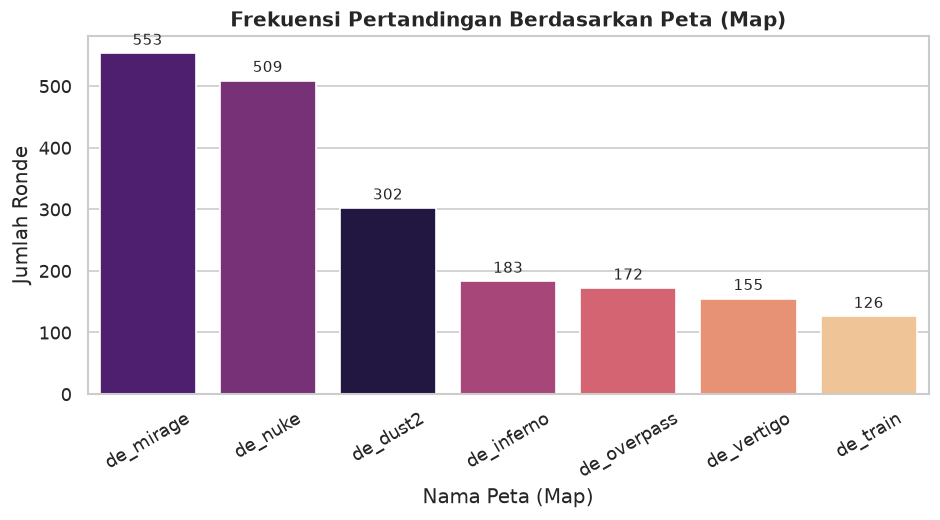

In [6]:
# 202431051 - Artika Aulia S
# 6. EDA: Distribusi Pertandingan Berdasarkan Peta (Map)
plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=df, x="map", order=df["map"].value_counts().index, palette="magma", hue="map", legend=False)
plt.title("Frekuensi Pertandingan Berdasarkan Peta (Map)", fontweight="bold")
plt.xlabel("Nama Peta (Map)")
plt.ylabel("Jumlah Ronde")
plt.xticks(rotation=30)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()


In [7]:
# 202431051 - Artika Aulia S
# 7. Pemisahan Fitur (X) dan Target (y) serta Train-Test Split
X = df.drop("round_winner", axis=1)
y = df["round_winner"].map({"T": 1, "CT": 0})

cat_cols = ["map", "bomb_planted"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Ukuran X_train: {X_train.shape}, Ukuran X_test: {X_test.shape}")


Ukuran X_train: (1600, 13), Ukuran X_test: (400, 13)


In [8]:
# 202431051 - Artika Aulia S
# 8. Desain Pipeline Pra-pemrosesan Data (StandardScaler & OneHotEncoder)
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)])
print("ColumnTransformer berhasil didefinisikan!")


ColumnTransformer berhasil didefinisikan!


In [ ]:
# 202431051 - Artika Aulia S
# 9. Optimasi Hyperparameter KNN Menggunakan GridSearchCV & 5-Fold Stratified CV
pipe_knn = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", KNeighborsClassifier())])

param_grid_knn = {
    "clf__n_neighbors": list(range(1, 26, 2)),
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring="accuracy", n_jobs=-1)
grid_knn.fit(X_train, y_train)

print(f"Parameter KNN Terbaik: {grid_knn.best_params_}")
print(f"Rata-rata Akurasi CV Terbaik: {grid_knn.best_score_:.4f}")


In [ ]:
# 202431051 - Artika Aulia S
# 10. Visualisasi Kurva Optimasi K vs Akurasi Cross-Validation
res_df = pd.DataFrame(grid_knn.cv_results_)
res_knn_uni = res_df[(res_df["param_clf__weights"] == "uniform") & (res_df["param_clf__metric"] == "manhattan")]

plt.figure(figsize=(7, 4))
plt.plot(res_knn_uni["param_clf__n_neighbors"], res_knn_uni["mean_test_score"], marker="o", color="#2ca02c", linewidth=2)
plt.title("GridSearchCV: Akurasi CV vs Nilai K (Metric Manhattan)", fontweight="bold")
plt.xlabel("Nilai K (Jumlah Tetangga Dekat)")
plt.ylabel("Rata-Rata Akurasi (5-Fold CV)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# 202431051 - Artika Aulia S
# 11. Pelatihan Model Gaussian Naive Bayes Terintegrasi Pipeline
pipe_nb = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", GaussianNB())
])
pipe_nb.fit(X_train, y_train)

cv_scores_nb = cross_val_score(pipe_nb, X_train, y_train, cv=cv, scoring="accuracy")
print(f"Rata-rata Akurasi CV Naive Bayes: {cv_scores_nb.mean():.4f} (+/- {cv_scores_nb.std():.4f})")


In [ ]:
# 202431051 - Artika Aulia S
# 12. Evaluasi Performa Model Terhadap Data Uji (Test Set)
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)
y_pred_nb = pipe_nb.predict(X_test)

print("=== K-NEAREST NEIGHBORS (KNN TEROPTIMASI) ===")
print(classification_report(y_test, y_pred_knn, target_names=["CT", "T"]))

print("=== GAUSSIAN NAIVE BAYES ===")
print(classification_report(y_test, y_pred_nb, target_names=["CT", "T"]))


In [ ]:
# 202431051 - Artika Aulia S
# 13. Visualisasi Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_nb = confusion_matrix(y_test, y_pred_nb)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["CT", "T"], yticklabels=["CT", "T"])
axes[0].set_title("Confusion Matrix: KNN Teroptimasi", fontweight="bold")
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Aktual (Ground Truth)")

sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[1],
            xticklabels=["CT", "T"], yticklabels=["CT", "T"])
axes[1].set_title("Confusion Matrix: Gaussian Naive Bayes", fontweight="bold")
axes[1].set_xlabel("Prediksi Model")
axes[1].set_ylabel("Aktual (Ground Truth)")

plt.tight_layout()
plt.show()


In [ ]:
# 202431051 - Artika Aulia S
# 14. Grafis Komparasi Metrik Evaluasi Performa Model
metrics_df = pd.DataFrame({
    "Model": ["KNN Teroptimasi", "KNN Teroptimasi", "KNN Teroptimasi", "KNN Teroptimasi",
              "Gaussian Naive Bayes", "Gaussian Naive Bayes", "Gaussian Naive Bayes", "Gaussian Naive Bayes"],
    "Metrik": ["Akurasi", "Presisi", "Recall", "F1-Score", "Akurasi", "Presisi", "Recall", "F1-Score"],
    "Nilai": [
        accuracy_score(y_test, y_pred_knn), precision_score(y_test, y_pred_knn), recall_score(y_test, y_pred_knn), f1_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb), precision_score(y_test, y_pred_nb), recall_score(y_test, y_pred_nb), f1_score(y_test, y_pred_nb)
    ]
})

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=metrics_df, x="Metrik", y="Nilai", hue="Model", palette=["#2ca02c", "#d62728"])
plt.title("Komparasi Metrik Evaluasi: KNN Teroptimasi vs Naive Bayes", fontweight="bold")
plt.ylim(0, 1.05)
plt.ylabel("Skor Performa (0.0 - 1.0)")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()


In [ ]:
# 202431051 - Artika Aulia S
# 15. Ringkasan Hasil Komparatif dan Kesimpulan Akhir
summary_data = {
    "Model": ["KNN Teroptimasi (K=1, Manhattan)", "Gaussian Naive Bayes (Pipeline)"],
    "Akurasi Data Uji": [accuracy_score(y_test, y_pred_knn), accuracy_score(y_test, y_pred_nb)],
    "Presisi (Kelas T)": [precision_score(y_test, y_pred_knn), precision_score(y_test, y_pred_nb)],
    "Recall (Kelas T)": [recall_score(y_test, y_pred_knn), recall_score(y_test, y_pred_nb)],
    "F1-Score (Kelas T)": [f1_score(y_test, y_pred_knn), f1_score(y_test, y_pred_nb)],
    "Rata-Rata CV (5-Fold)": [grid_knn.best_score_, cv_scores_nb.mean()]
}
summary_df = pd.DataFrame(summary_data)
print("=== TABEL RINGKASAN HASIL PERBANDINGAN MODEL ===")
summary_df
